In [48]:
import functools
import os
import sys

from ultralytics import YOLO
import pandas as pd

sys.path.append("..")
import ultralytics_validator_wrapper
from tflite_inference import TFLiteInferer
from tflite_inference_input_adapter import TFLiteInferenceWithInputAdapter

pd.options.display.float_format = '{:.3f}'.format

%matplotlib inline
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [49]:
WEIGHTS_PTH = "../results/filtered_v3_margin_15_reduced_quality/weights/best.pt"

BASE_PTH = "/home/klymy/projects/researches/people_detection_pg2/quality_reduce_comparison/cam4_poc_15_blurred_grayscale"
BAELINE_BASE_PTH = "/home/klymy/projects/researches/people_detection_pg2/quality_reduce_comparison/cam4_poc_15"

VAL_PTH = os.path.join(BASE_PTH, "project_pg.yaml")
BASELINE_VAL_PTH = os.path.join(BAELINE_BASE_PTH, "project_pg.yaml")

CONF_TH = 0.35
IOU_TH = 0.5

args = dict(
    data=VAL_PTH,
    task="pose",
    device=[0],
    batch=128,
    verbose=False,
    conf=CONF_TH,
    iou=IOU_TH,
    imgsz=320,
    model="val",
    rect=False,
    single_cls=False,
)

args_baseline = args.copy()
args_baseline["data"] = BASELINE_VAL_PTH

In [50]:
model = YOLO(WEIGHTS_PTH)

val: Scanning /home/klymy/projects/researches/people_detection_pg2/quality_reduce_comparison/cam4_poc_15_blurred_grayscale/labels/val.cache... 191 images, 5 backgrounds, 0 corrupt: 100%|██████████| 191/191 [00:00<?, ?it/s]
tst validation: 100%|██████████| 2/2 [00:02<00:00,  1.47s/it]


                   all        191        417      0.848      0.774      0.862      0.624      0.892      0.795      0.882      0.879
   task    F1     P     R  MAP@50
0   box 0.809 0.848 0.774   0.862
1  pose 0.841 0.892 0.795   0.882


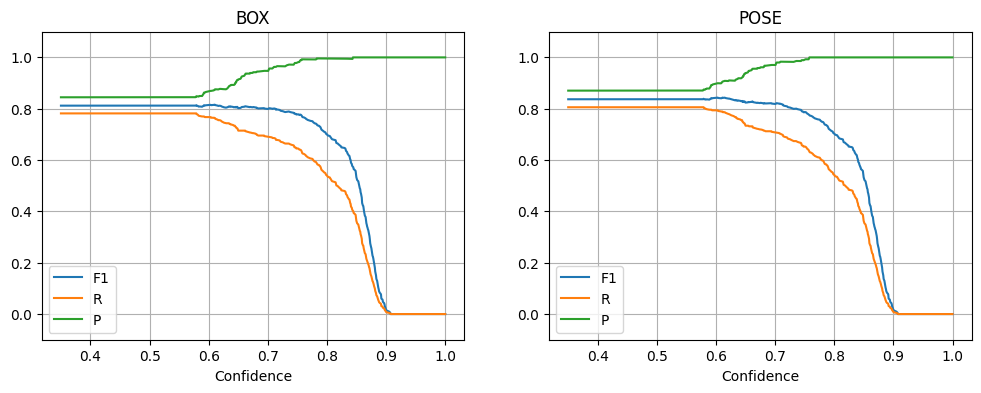

In [51]:
ultralytics_validator_wrapper.validate_model(
    args,
    model,
    functools.partial(ultralytics_validator_wrapper.predict_ultralytics, model, args),
)

In [52]:
inferer = TFLiteInferer(
    yolo_pth="../results/filtered_v3_margin_15_reduced_quality/weights/best_saved_model/best_full_integer_quant.tflite",
    head_pth="../results/filtered_v3_margin_15_reduced_quality/weights/head_saved_model/head_float32.tflite",
    conf_th=CONF_TH,
    iou_th=IOU_TH,
    imgsz=320,
)

val: Scanning /home/klymy/projects/researches/people_detection_pg2/quality_reduce_comparison/cam4_poc_15_blurred_grayscale/labels/val.cache... 191 images, 5 backgrounds, 0 corrupt: 100%|██████████| 191/191 [00:00<?, ?it/s]
tst validation: 100%|██████████| 2/2 [00:07<00:00,  3.86s/it]


                   all        191        417      0.941      0.724      0.851      0.611      0.966      0.743      0.865      0.863
   task    F1     P     R  MAP@50
0   box 0.818 0.941 0.724   0.851
1  pose 0.840 0.966 0.743   0.865


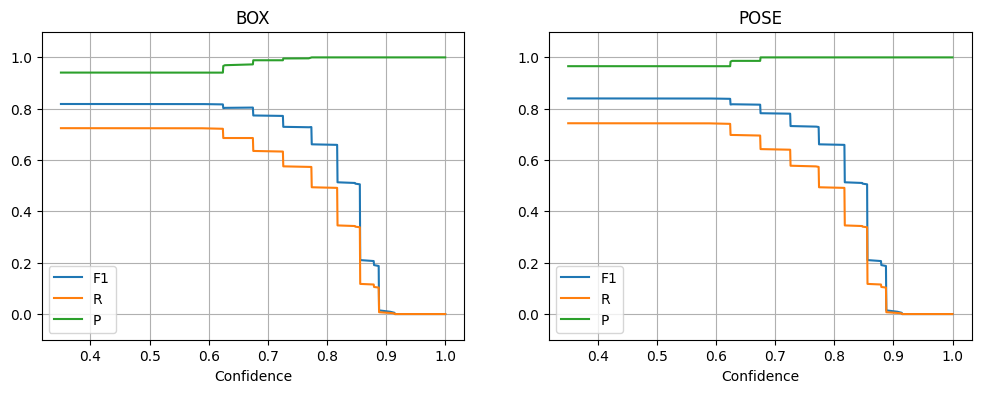

In [53]:
ultralytics_validator_wrapper.validate_model(
    args,
    model,
    functools.partial(ultralytics_validator_wrapper.predict_tflite, inferer, args)
)

In [54]:
inferer_adapter = TFLiteInferenceWithInputAdapter(
    yolo_pth="../results/filtered_v3_margin_15_reduced_quality/weights/best_saved_model/best_full_integer_quant.tflite",
    head_pth="../results/filtered_v3_margin_15_reduced_quality/weights/head_saved_model/head_float32.tflite",
    adapter_pth="../input_adapter/input_adapter_full_integer_quant.tflite",
    conf_th=CONF_TH,
    iou_th=IOU_TH,
    imgsz=320,
)

val: Scanning /home/klymy/projects/researches/people_detection_pg2/quality_reduce_comparison/cam4_poc_15/labels/val.cache... 191 images, 5 backgrounds, 0 corrupt: 100%|██████████| 191/191 [00:00<?, ?it/s]
tst validation:   0%|          | 0/2 [00:00<?, ?it/s]

tst validation: 100%|██████████| 2/2 [00:08<00:00,  4.37s/it]


                   all        191        417      0.925      0.794      0.884      0.616       0.95      0.815        0.9      0.899
   task    F1     P     R  MAP@50
0   box 0.854 0.925 0.794   0.884
1  pose 0.877 0.950 0.815   0.900


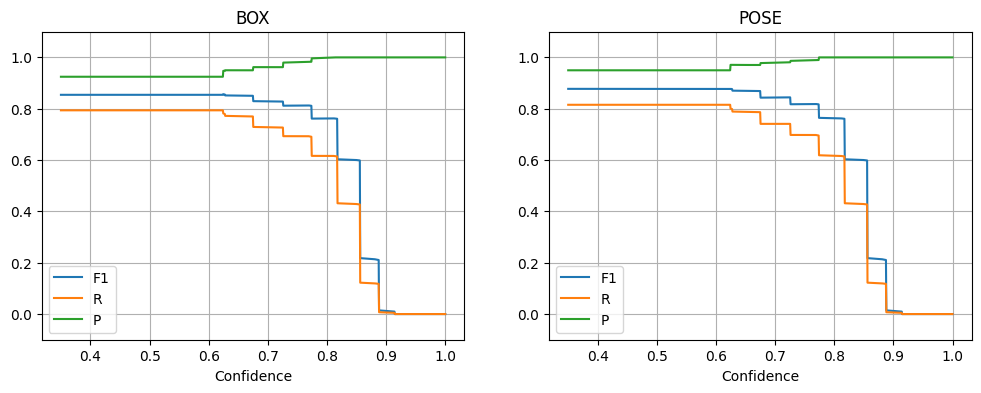

In [55]:
ultralytics_validator_wrapper.validate_model(
    args_baseline,
    model,
    functools.partial(ultralytics_validator_wrapper.predict_tflite, inferer_adapter, args_baseline)
)